In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

sc.settings.set_figure_params(dpi = 160, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')
plt.rcParams["figure.figsize"] = [6,6]
plt.rcParams["pdf.fonttype"] = 42 # add pdf text as one piece instead of letter by letter

In [2]:
sb.set_palette('colorblind')

In [3]:
cell_types = ['HSC_MPP','CYCLING_MPP']

palette_dict = dict(zip(cell_types, sb.color_palette("colorblind")))

In [4]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [5]:
# figure directory
fig_path = 'figure/'
sc.settings.figdir = fig_path

# Load data

In [8]:
adata = sc.read('write/SPI1_INDUCIBLE_celltypist.h5ad')

In [9]:
adata.obs['sanger_sample_ID'] =adata.obs['sanger_sample_ID'].astype('str')
adata.obs['sanger_sample_ID'] = [smp[19:] for smp in adata.obs['sanger_sample_ID']]

# Celltype annotation

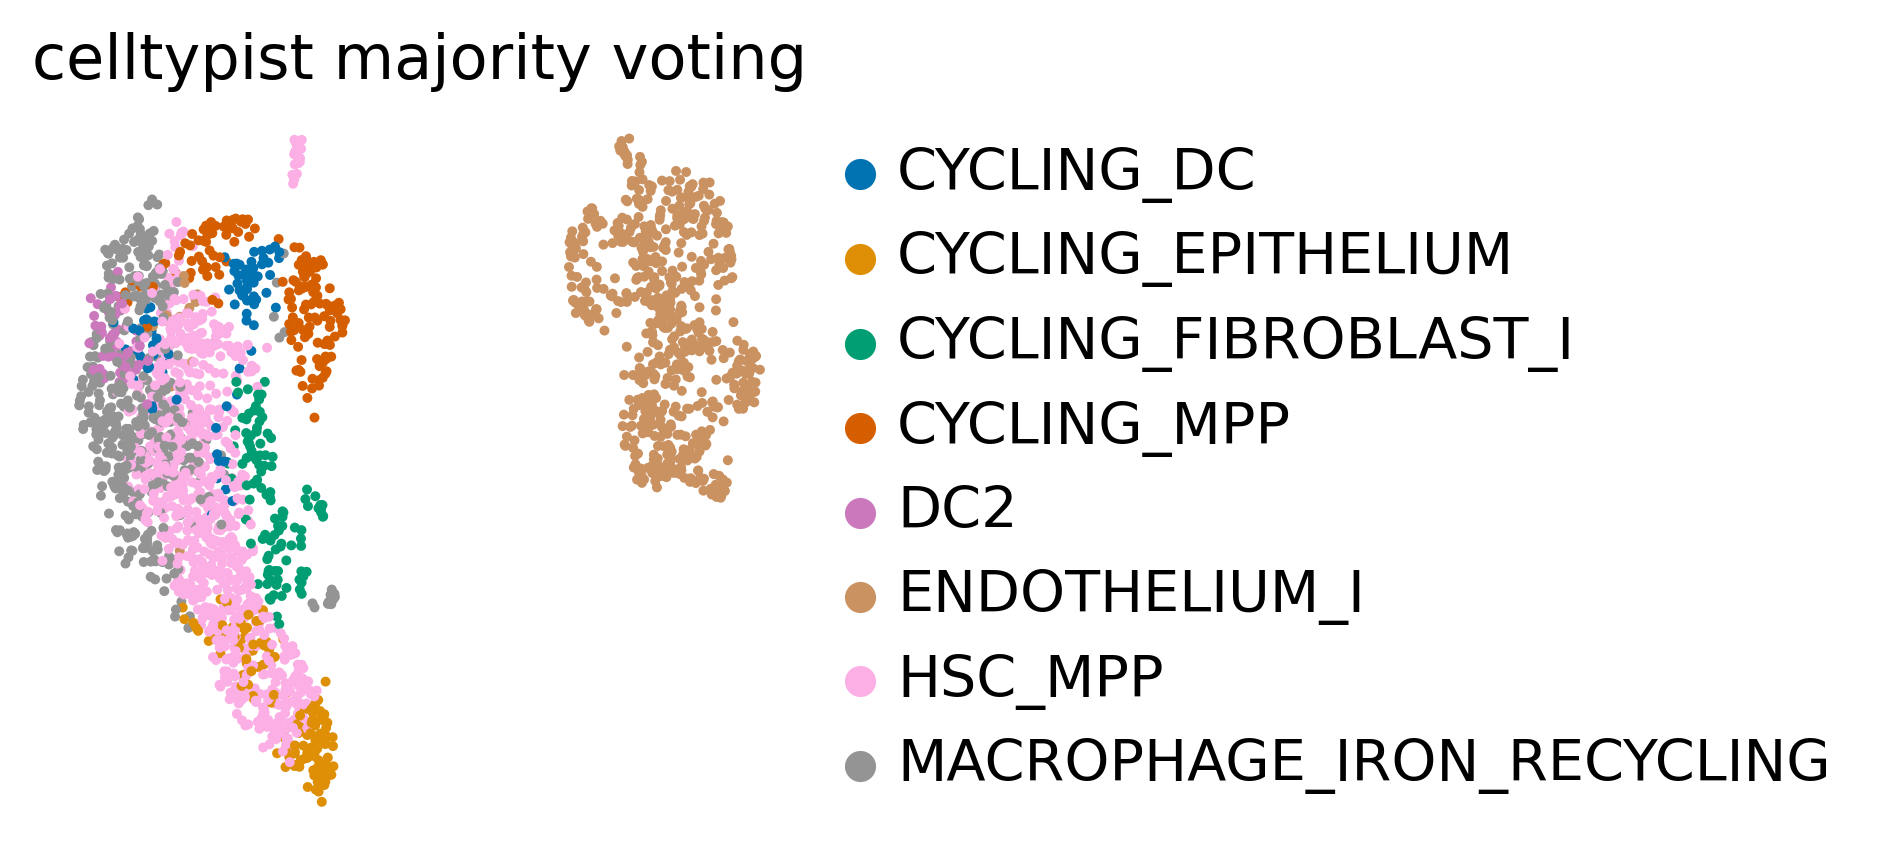

In [21]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(adata, color=['majority_voting'], 
           frameon = False, size=20,
           title = ['celltypist majority voting'], save = 'INDUCIBLE_SPI1_celltypist.pdf')

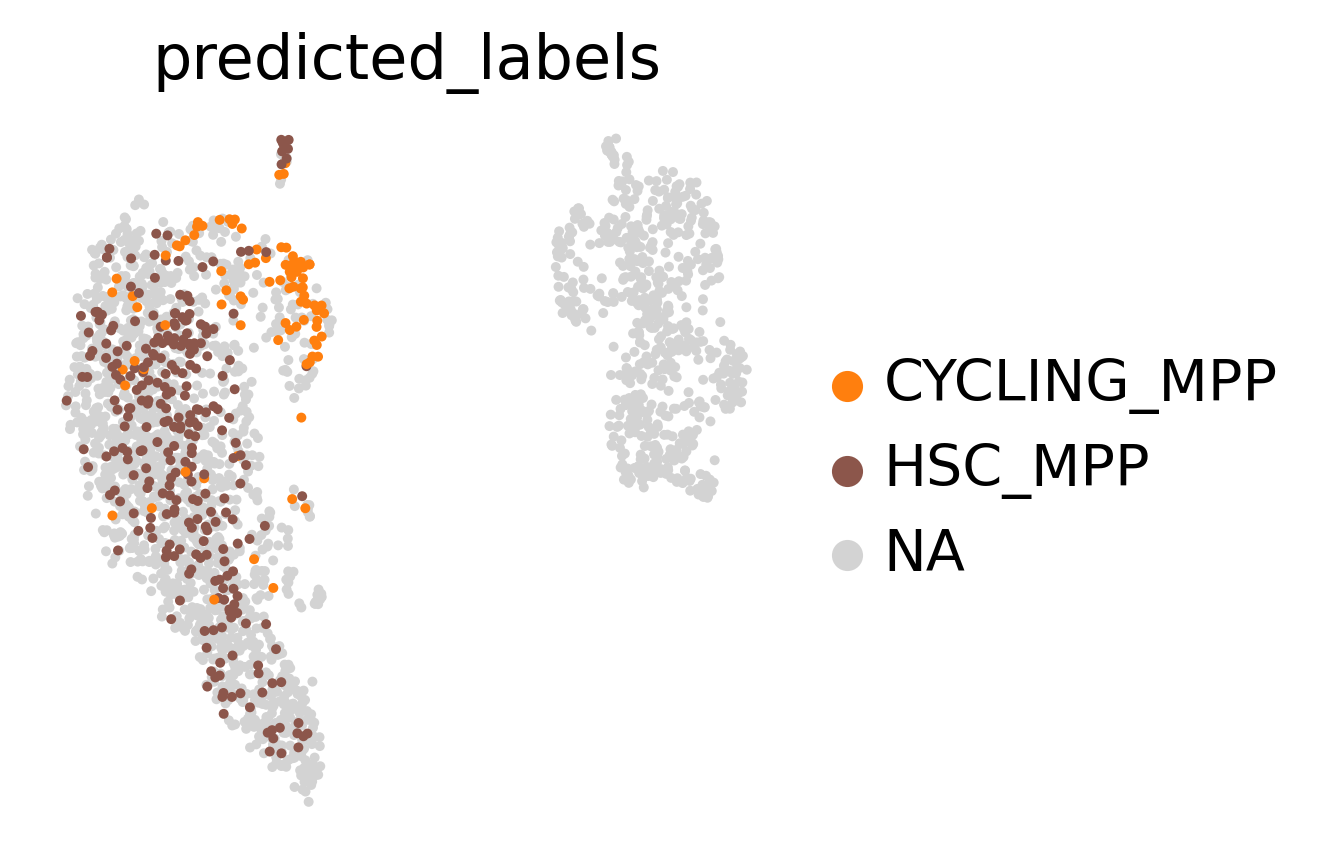

In [28]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(adata, color=['predicted_labels'], groups = ['CYCLING_MPP','HSC_MPP'],size=20, frameon=False, 
           palette = 'tab10',
           save = 'SPI1_inducible_celltypist_prediction.pdf')

In [10]:
sc.tl.leiden(adata, resolution =0.5)

/tmp/ipykernel_484571/1078223239.py:1: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata, resolution =0.5)


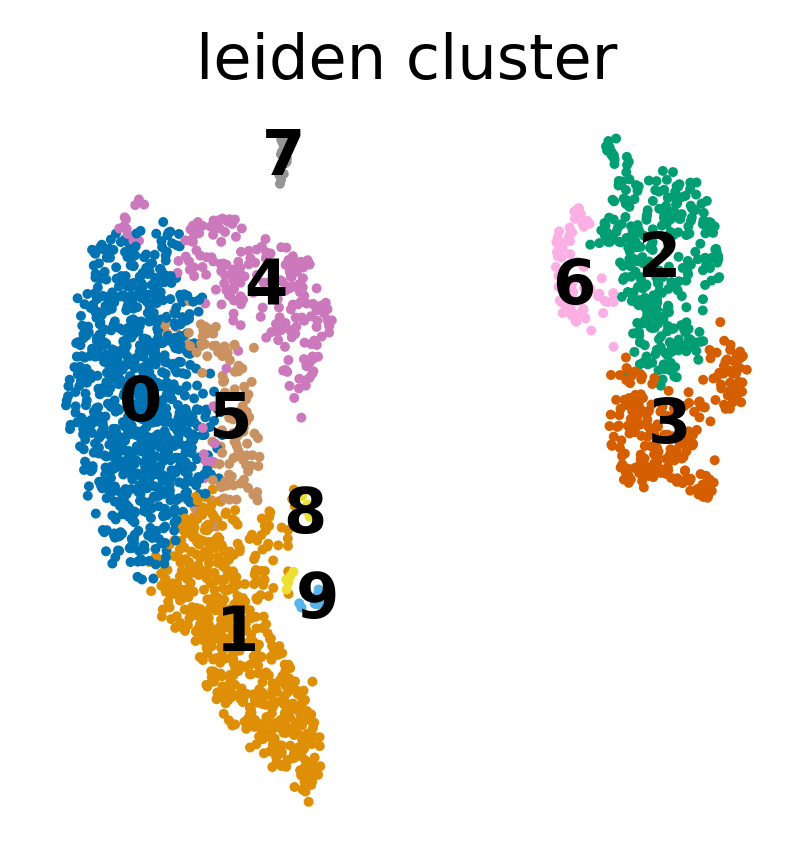

In [29]:
sc.pl.umap(adata, color=['leiden'], title = ['leiden cluster'], size=20, legend_loc = 'on data', frameon=False, 
          save = 'SPI1_inducible_leiden.pdf')

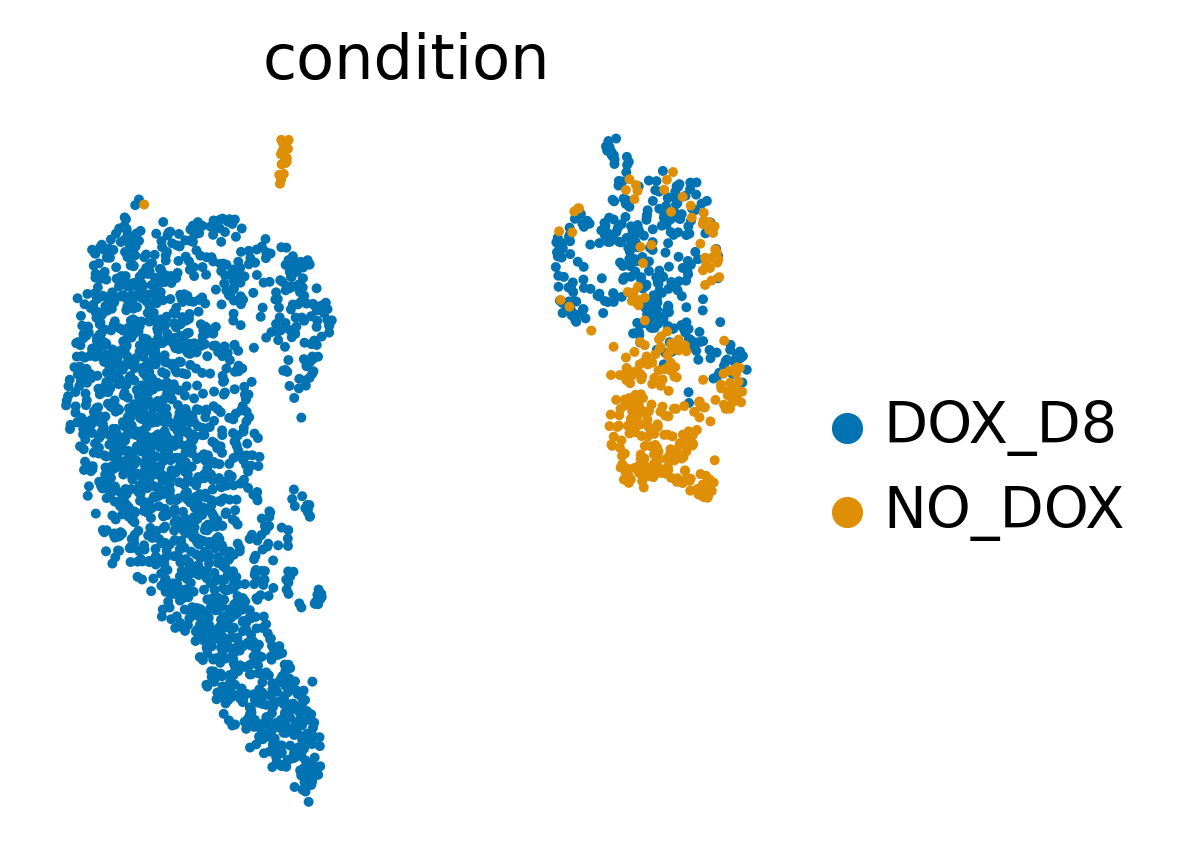

In [27]:
sc.pl.umap(adata, color=['sanger_sample_ID'],title = 'condition',size=20, frameon=False, legend_loc='right margin',
           save = 'SPI1_inducible_sample.pdf')

## Marker genes

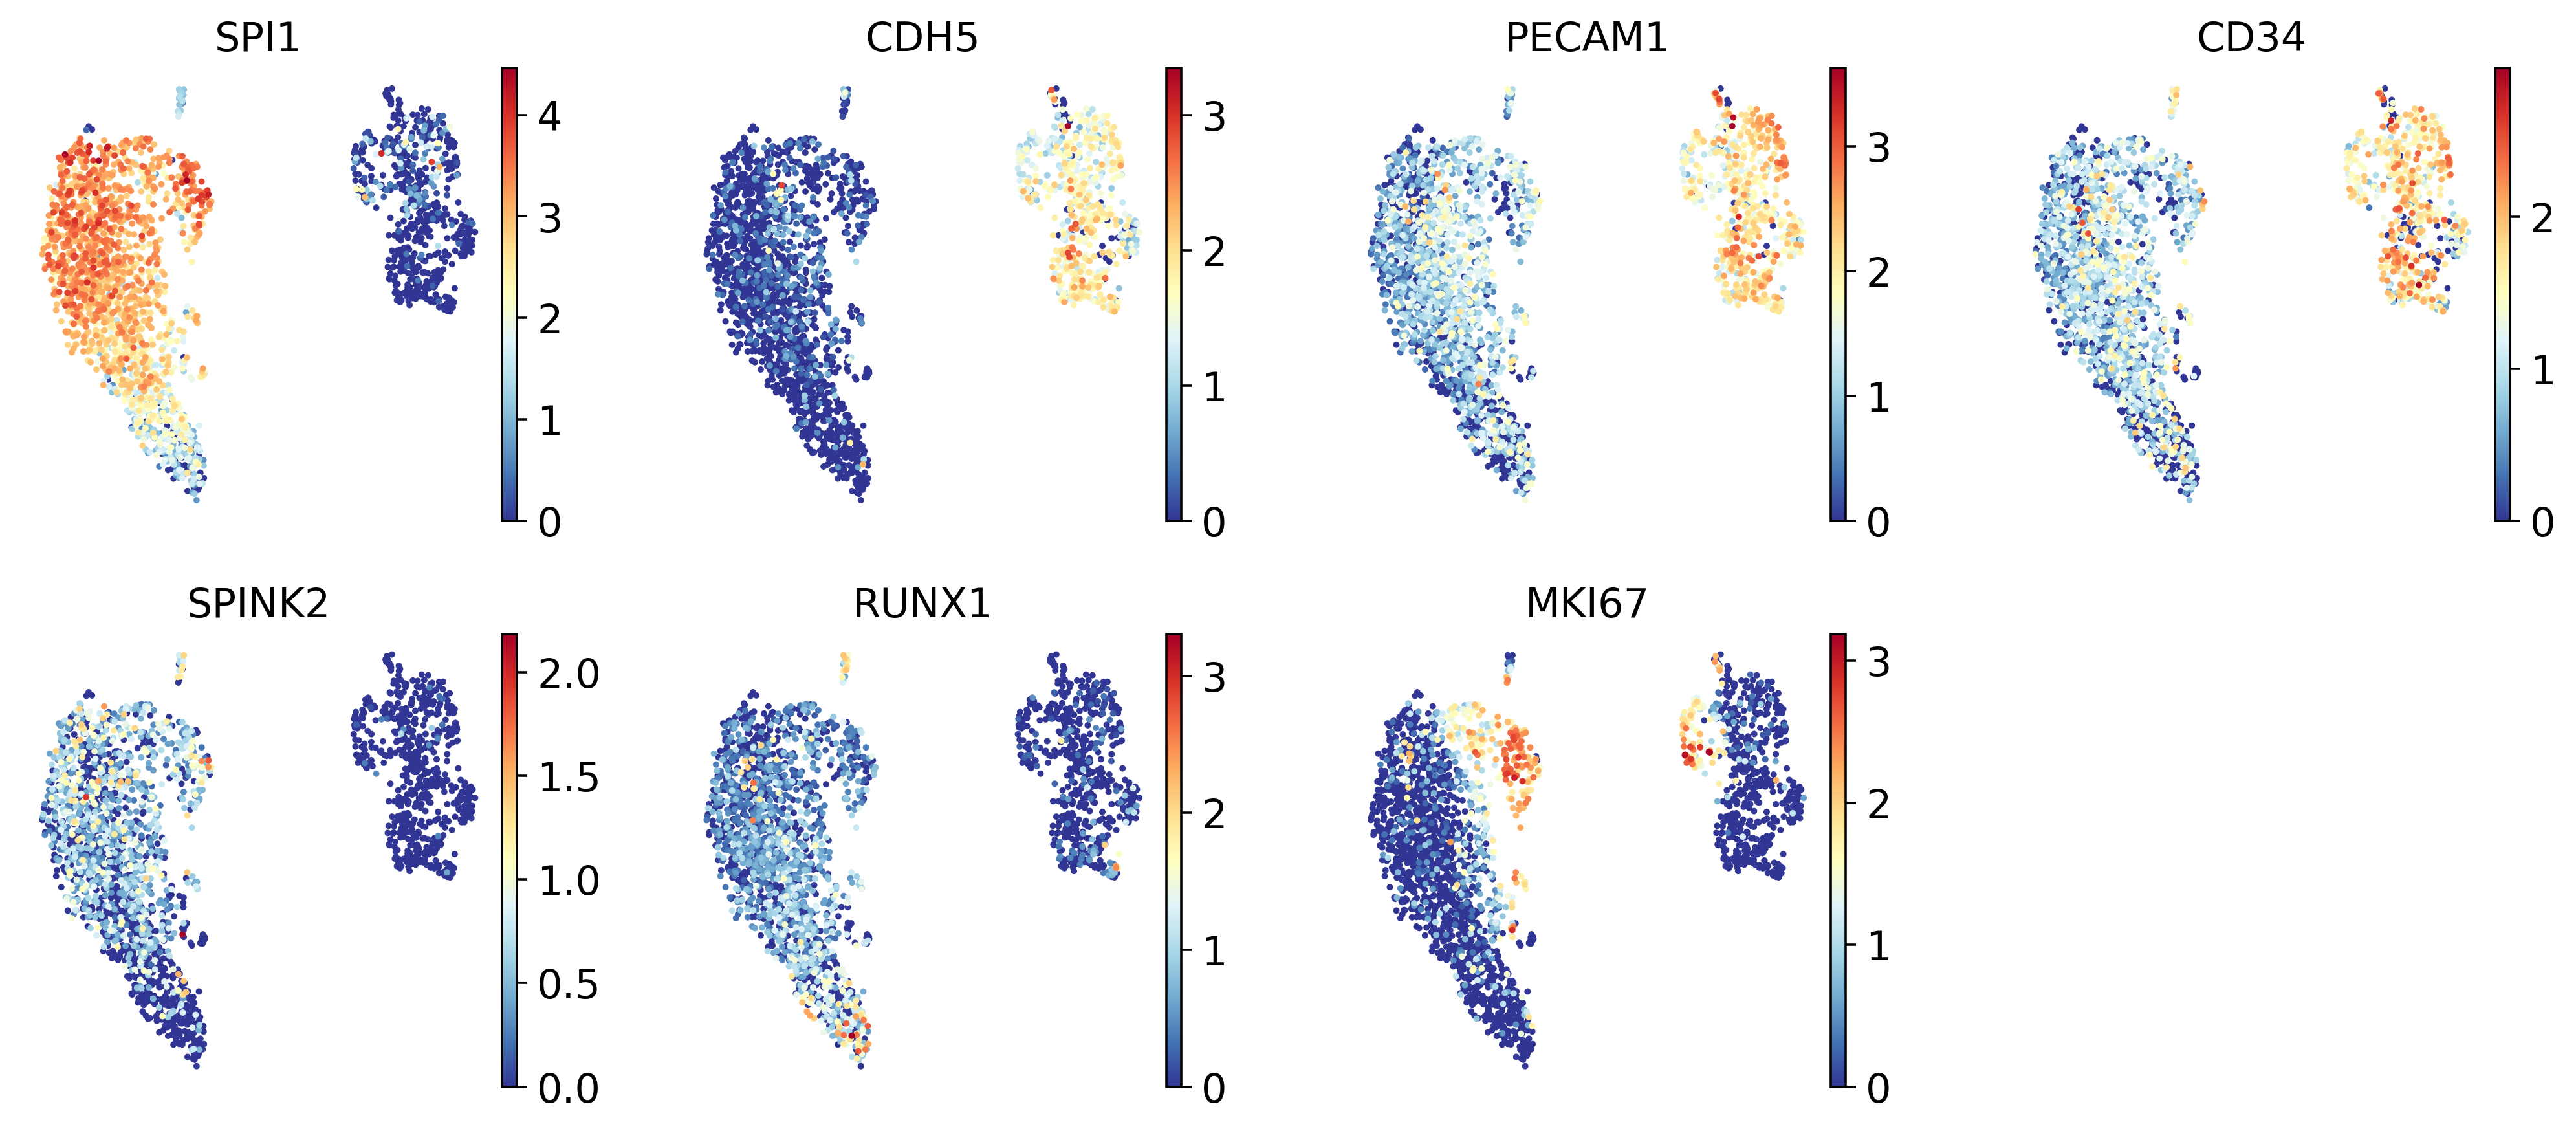

In [27]:
genes = ['SPI1',
         'CDH5','PECAM1','CD34',# endothelium
         'SPINK2','RUNX1',#HSC
         'MKI67']
sc.pl.umap(adata, color=genes, ncols=4, size=20,
           frameon=False)

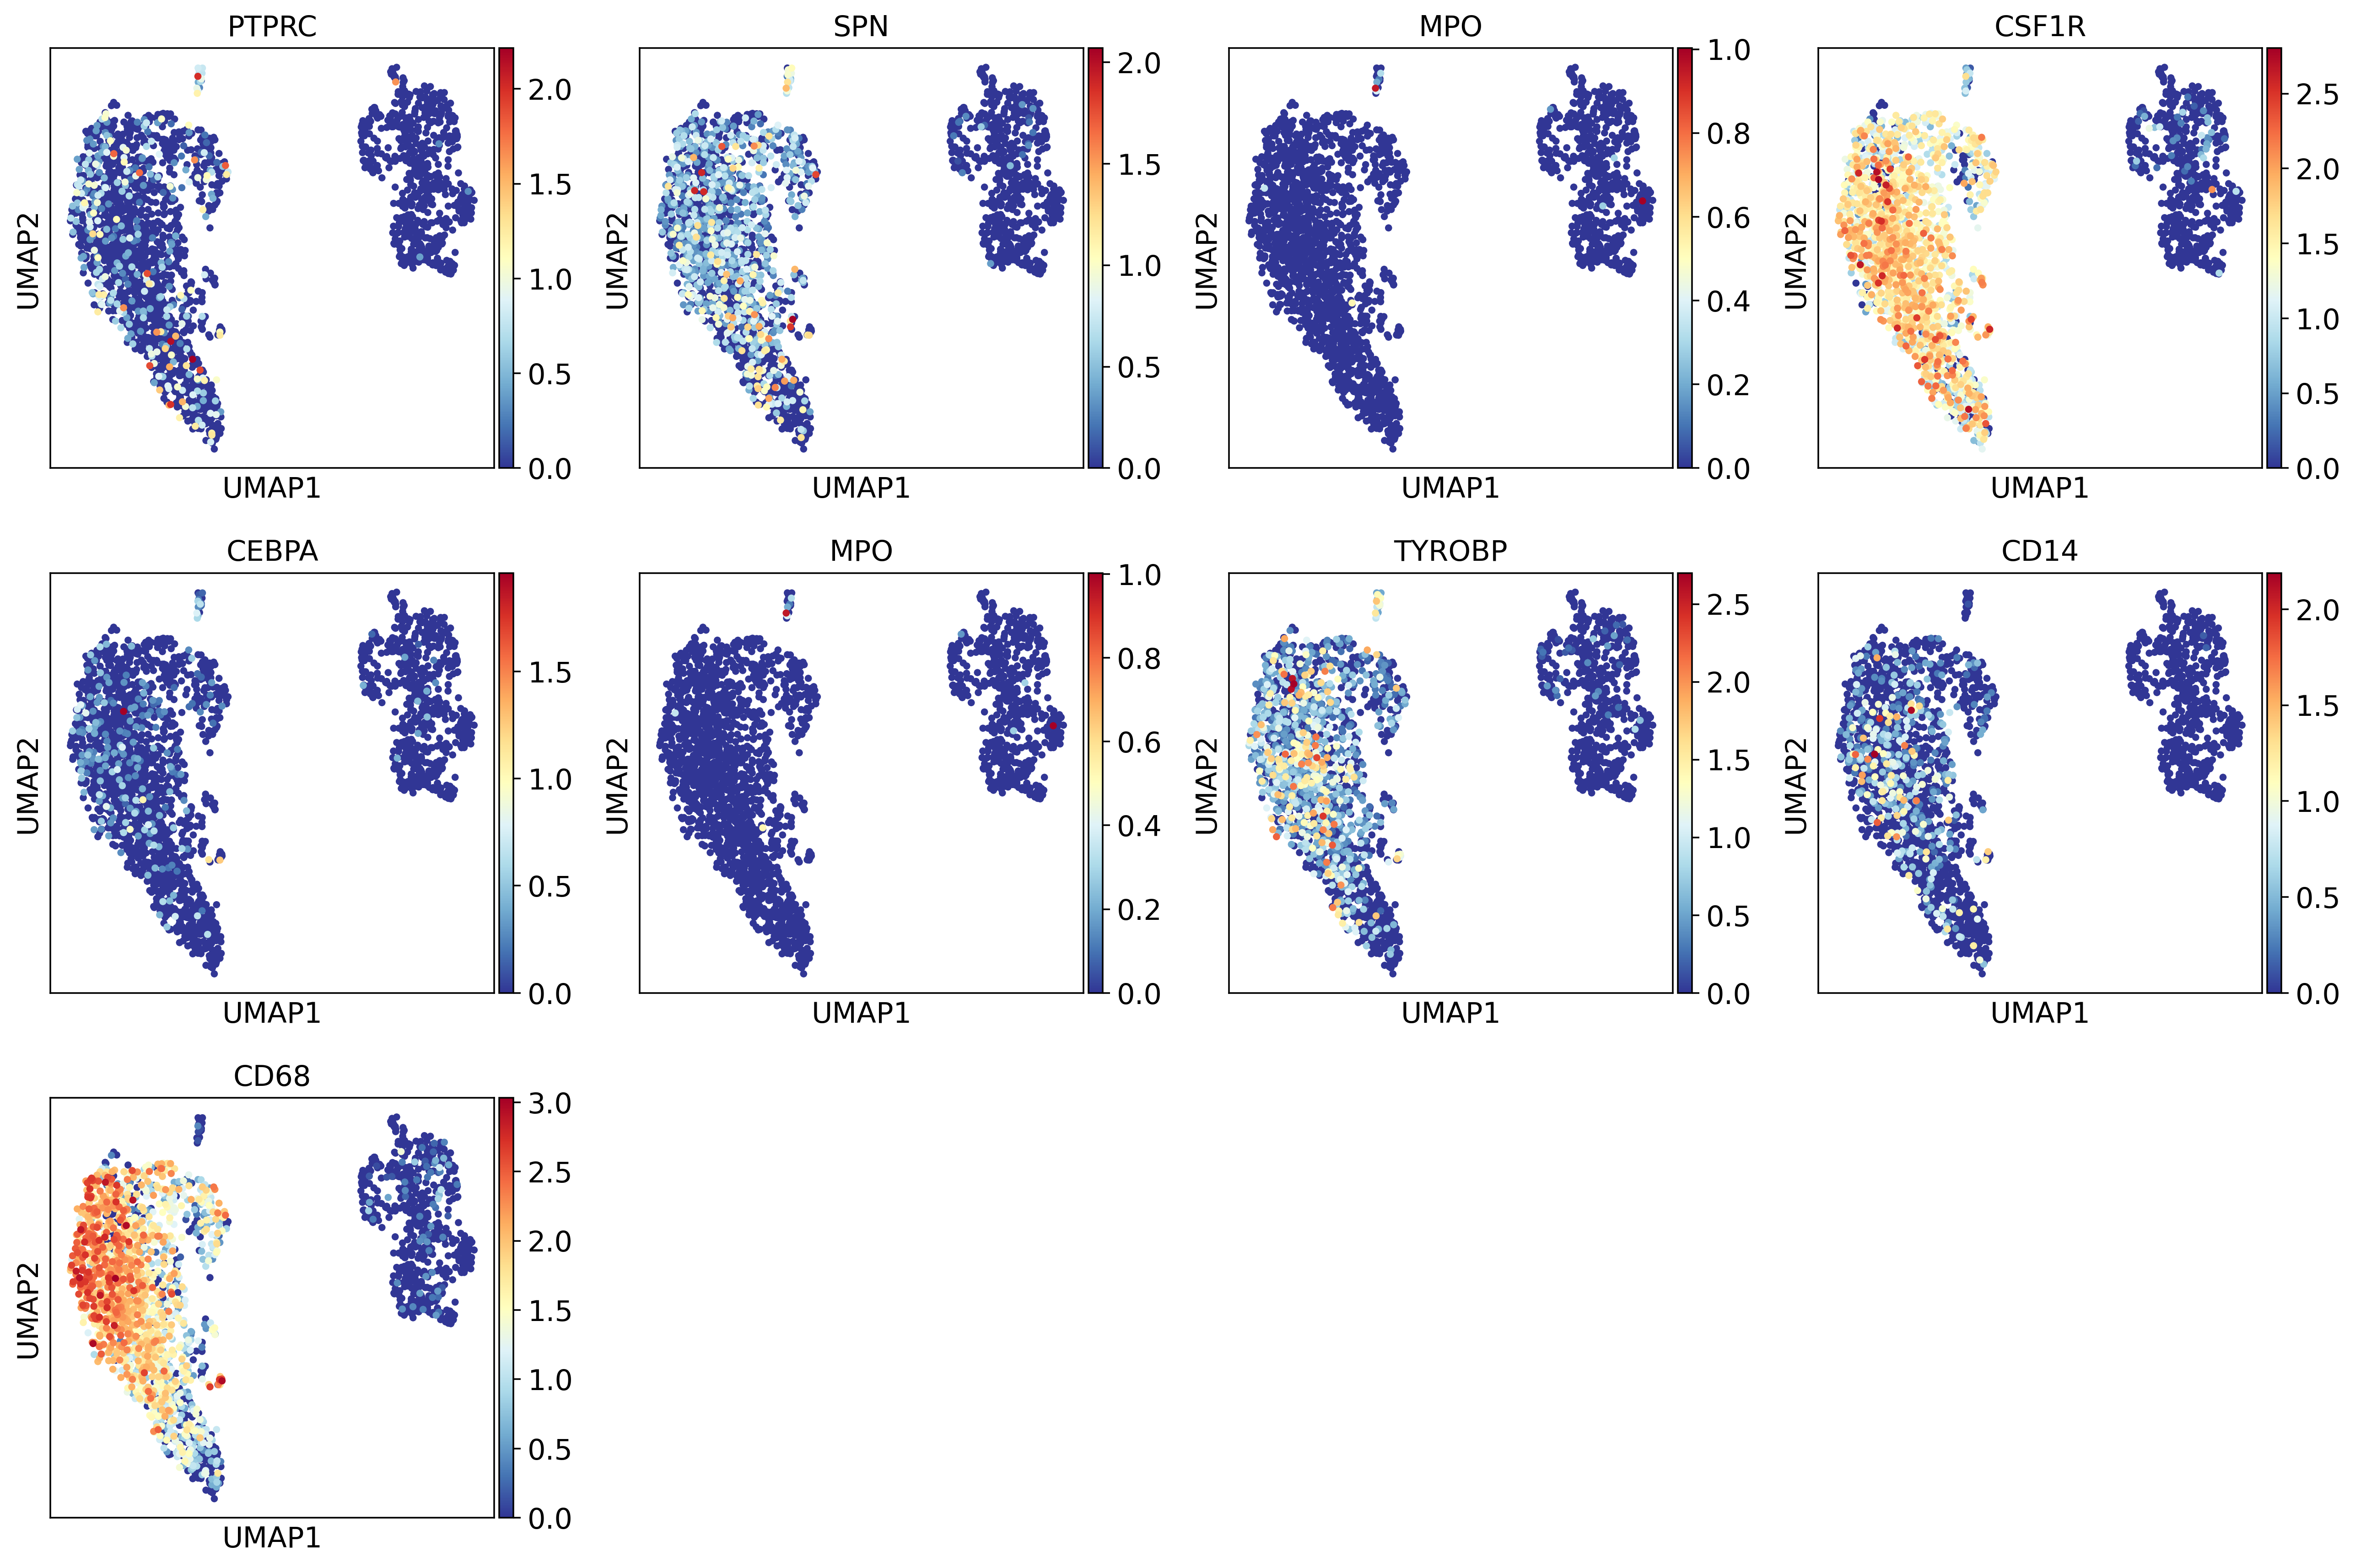

In [41]:
genes = ['PTPRC','SPN','MPO','CSF1R','CEBPA','MPO','TYROBP','CD14','CD68']
sc.pl.umap(adata, color=genes)

## leiden cluster 0, 1, 5, 7, 8, 9 - HSC_MPP; 4 - CYCLING_MPP; 2,3,6 - endothelium

In [13]:
# group cell types into broad groups 
adata.obs['annot'] = 'ENDOTHELIUM'
adata.obs.loc[adata.obs['leiden'].isin(['0','1','5','7','8','9']),'annot'] = 'HSC_MPP'
adata.obs.loc[adata.obs['leiden'].isin(['4']),'annot'] = 'CYCLING_MPP'

In [18]:
adata.obs['annot'] =adata.obs['annot'].cat.reorder_categories(['HSC_MPP',
                                                            'CYCLING_MPP', 'ENDOTHELIUM'  ]) 

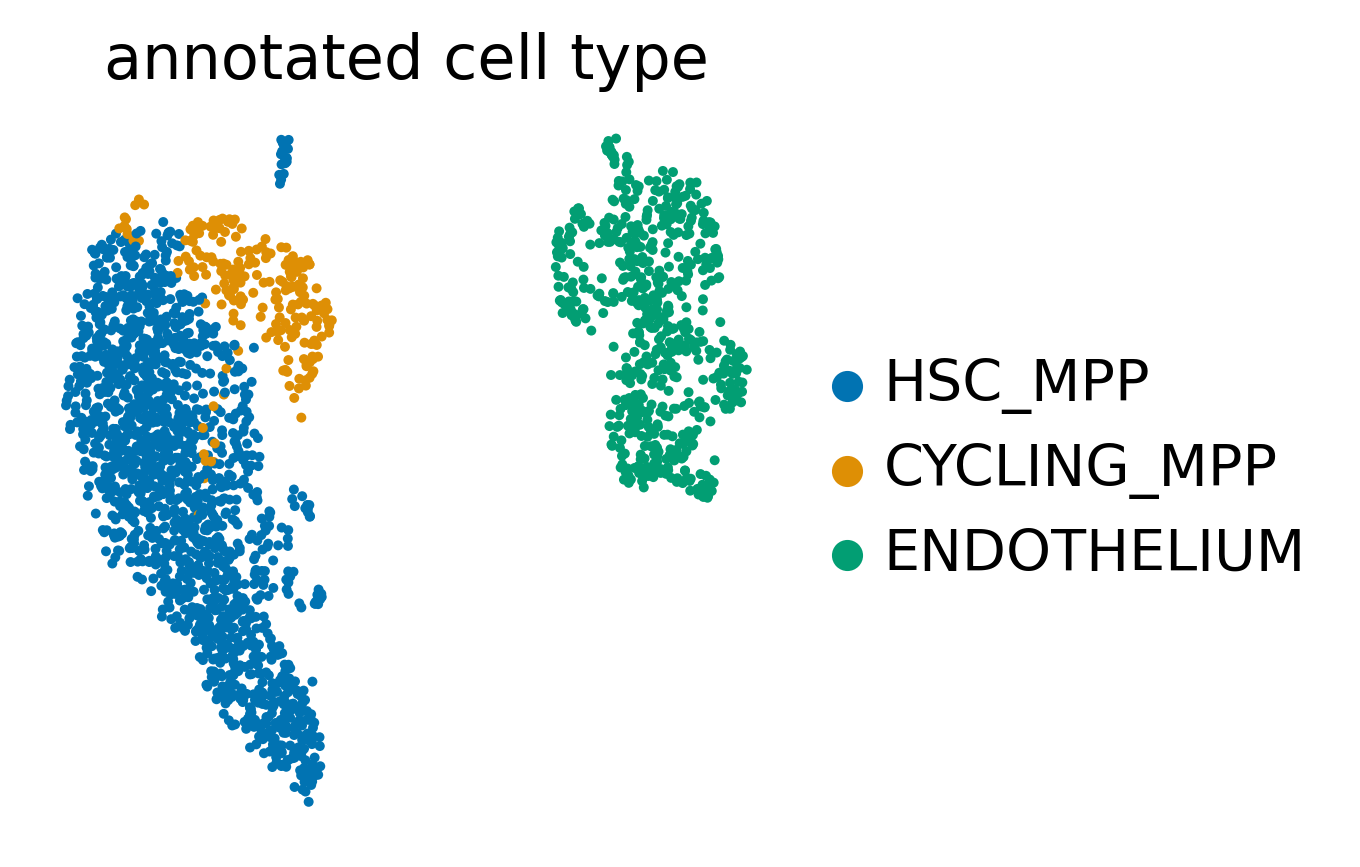

In [19]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(adata, color=['annot'], title = 'annotated cell type', 
           size=20,
           frameon=False, 
           save = 'annotated_spi1_inducible.pdf')

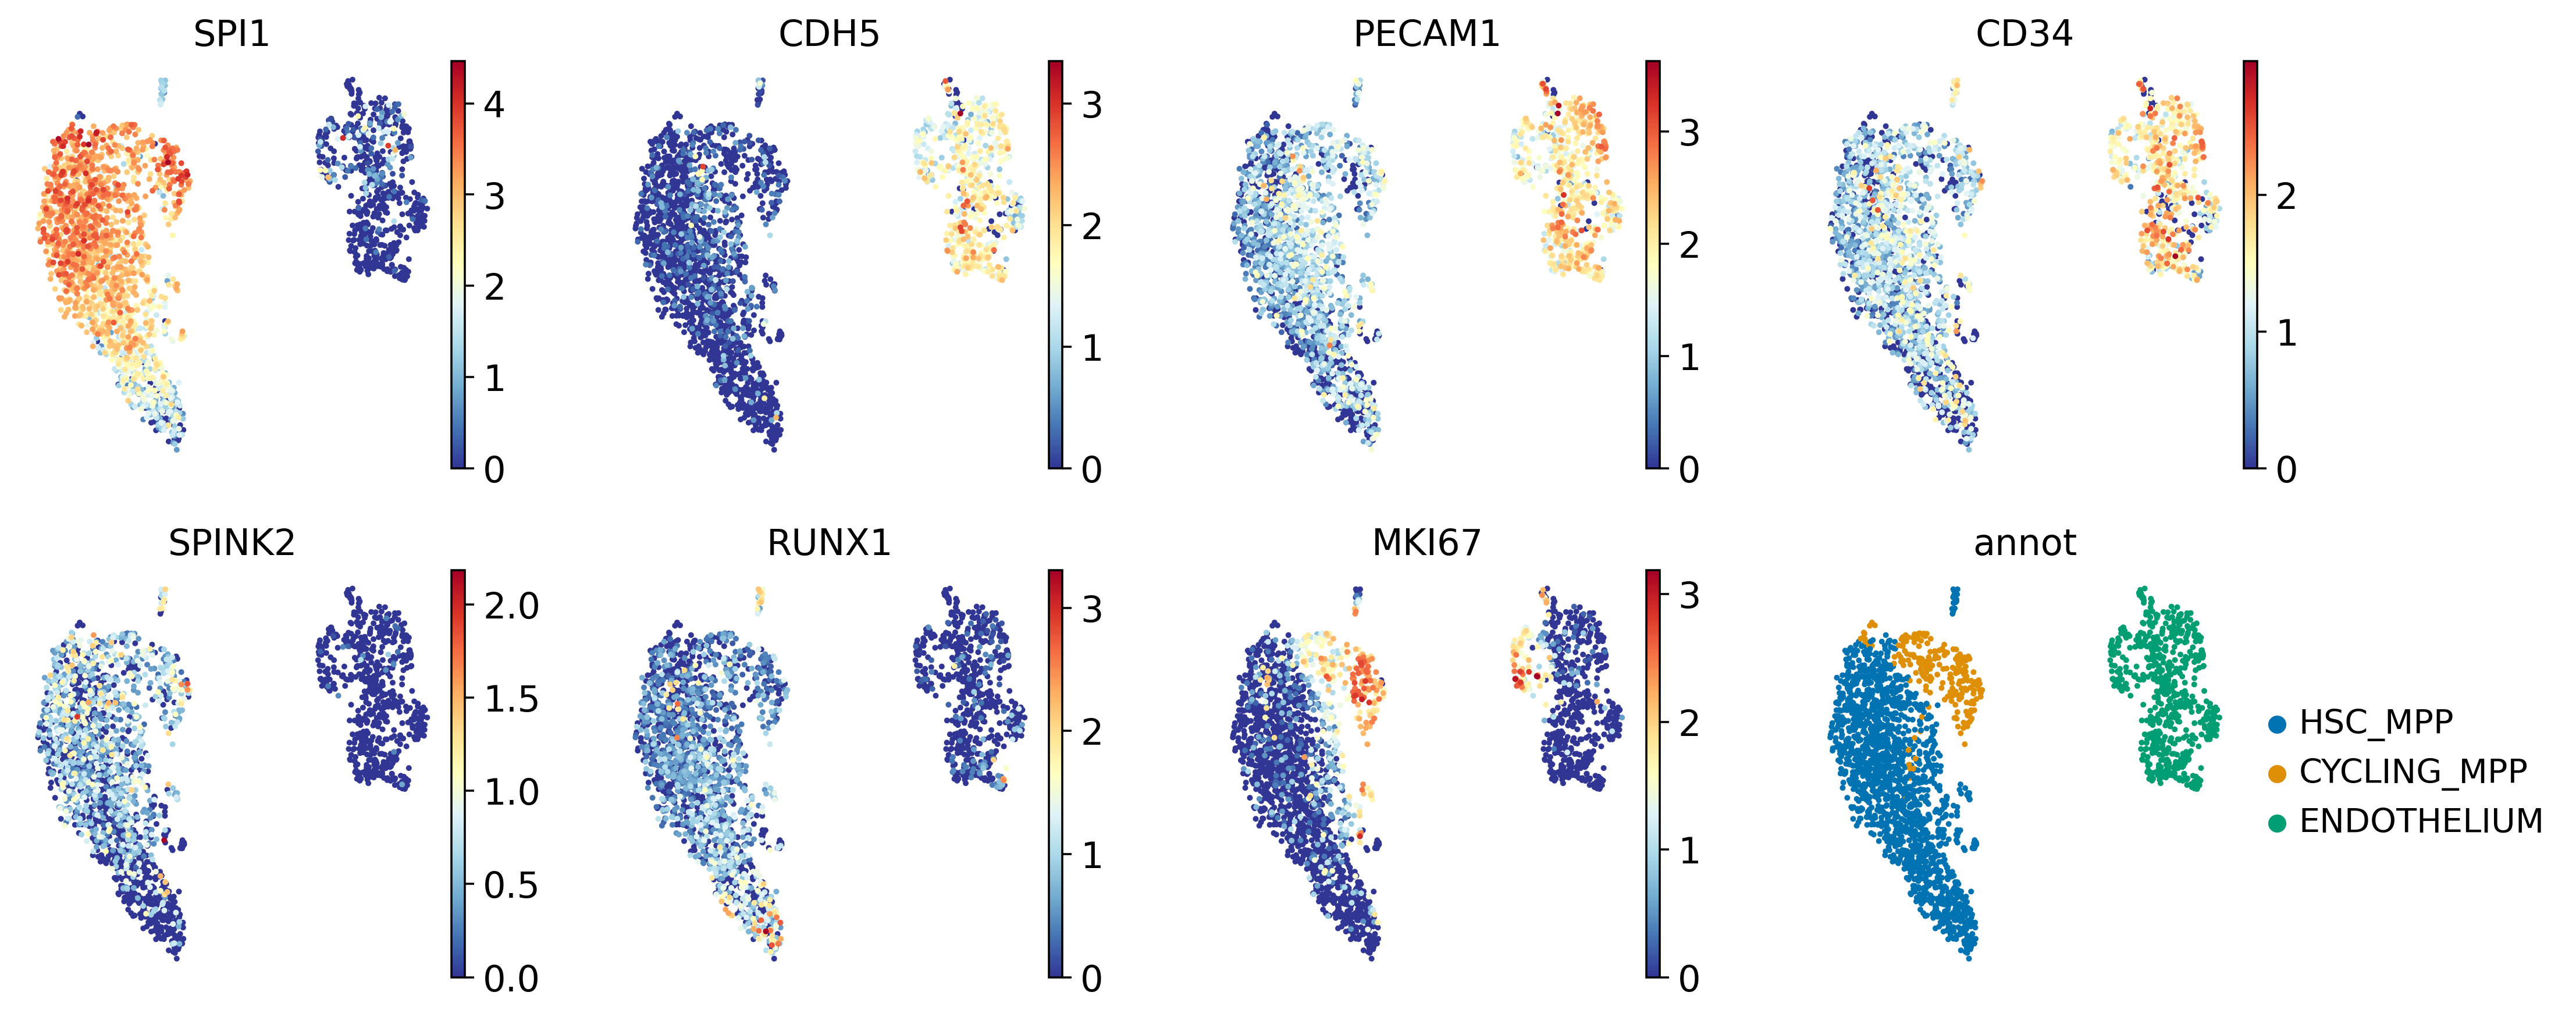

In [26]:
genes = ['SPI1',
         'CDH5','PECAM1','CD34',# endothelium
         'SPINK2','RUNX1',#HSC
         'MKI67', 'annot']
sc.pl.umap(adata, color=genes, ncols=4, size=20,
           frameon=False,
           save= 'inducible_spi1_marker.pdf')

In [46]:
df = adata.obs[['sanger_sample_ID', 'annot']]

In [47]:
# count cells
df_counts = (
    df
    .groupby(['sanger_sample_ID', 'annot'])
    .size()
    .reset_index(name='count')
)

# compute percentages within each antibody
df_counts['percent'] = (
    df_counts
    .groupby('sanger_sample_ID')['count']
    .transform(lambda x: 100 * x / x.sum())
)

/tmp/ipykernel_3061598/2169766357.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['sanger_sample_ID', 'annot'])
/tmp/ipykernel_3061598/2169766357.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('sanger_sample_ID')['count']


/tmp/ipykernel_3061598/2173580933.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[74.48931116  6.08974359]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  bottom[subset["sanger_sample_ID"]] += subset["percent"].values


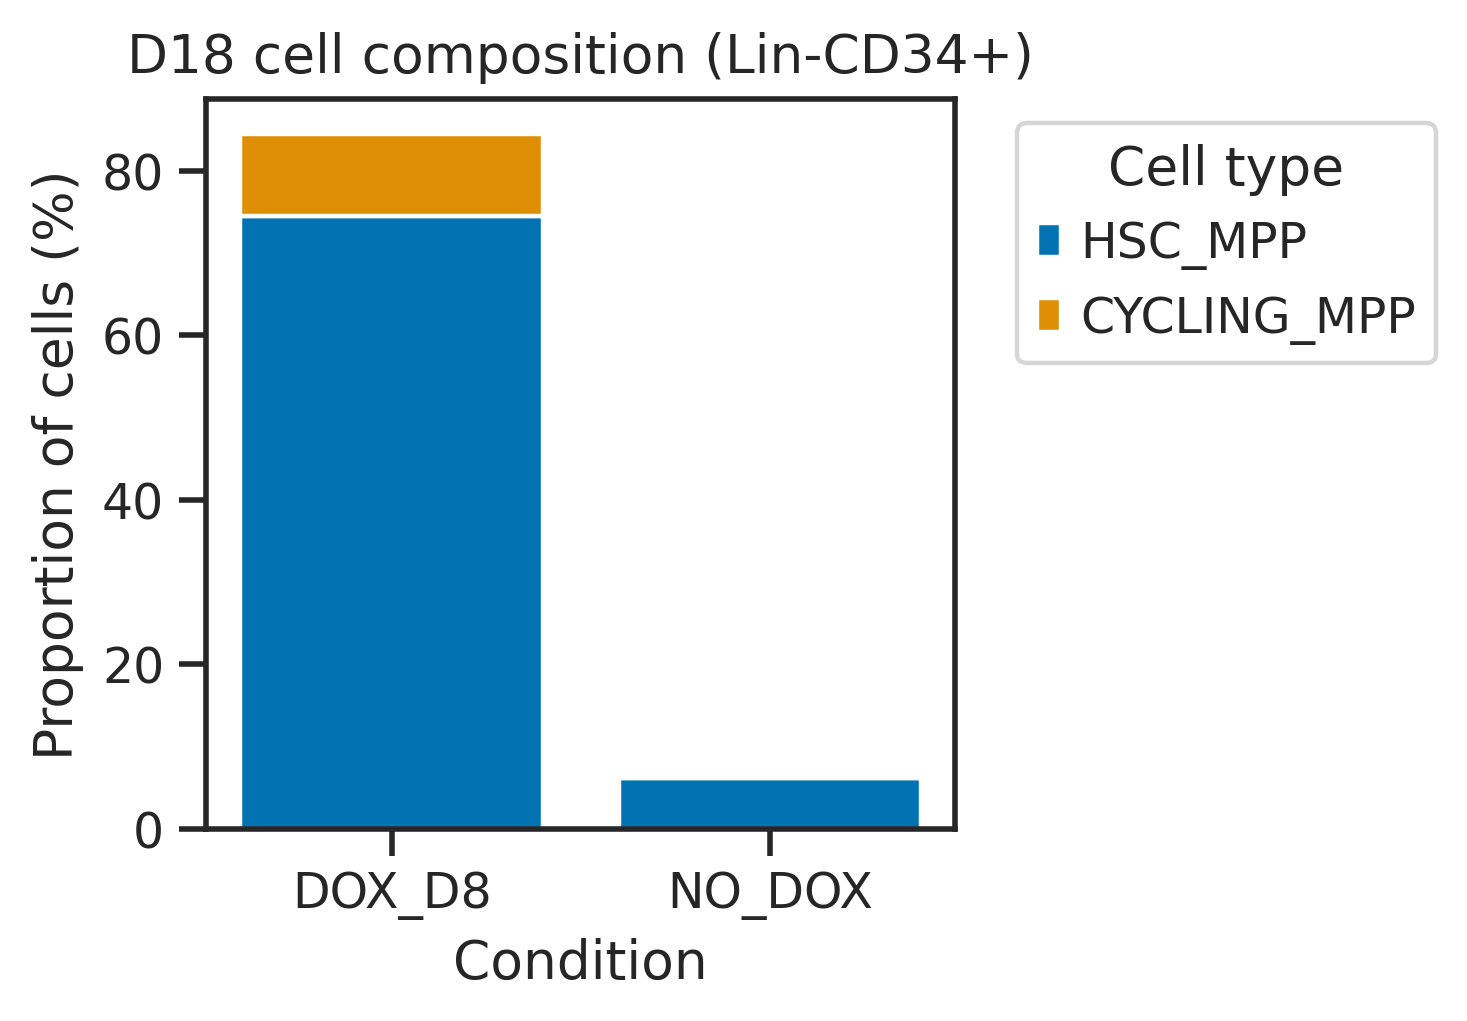

In [49]:
sb.set_theme(style = 'ticks')
plt.figure(figsize=(3, 3))

bottom = pd.Series(0, index=df_counts["sanger_sample_ID"].unique())

for cell_type in ['HSC_MPP','CYCLING_MPP']:
    subset = df_counts[df_counts["annot"] == cell_type]
    plt.bar(
        subset["sanger_sample_ID"],
        subset["percent"],
        bottom=bottom[subset["sanger_sample_ID"]].values,
        label=cell_type,
        color=palette_dict[cell_type]
    )
    bottom[subset["sanger_sample_ID"]] += subset["percent"].values

plt.ylabel("Proportion of cells (%)")
plt.xlabel("Condition")
plt.title('D18 cell composition (Lin-CD34+)')
plt.legend(title="Cell type", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.savefig(fig_path+"D18_celltypes_INDUCIBLE_SPI1.pdf", bbox_inches='tight')

In [20]:
adata.write_h5ad('write/SPI1_INDUCIBLE_annotated.h5ad')

In [50]:
# take predicted to be HSC/MPP and from DOX_D8
hsc = adata[np.array(adata.obs['annot'].isin(['CYCLING_MPP','HSC_MPP'])) & np.array(adata.obs['sanger_sample_ID']=='DOX_D8')]
hsc.write_h5ad('write/SPI1_INDUCIBLE_HSC.h5ad')

In [51]:
Counter(hsc.obs['sanger_sample_ID'])

Counter({'DOX_D8': 1779})